In [ ]:
# Forecast of products demand based on M5 dataset

In [22]:
from statistics import correlation

import pandas as pd
import numpy as np

df = pd.read_csv('data/df_dml_new.csv')
print(df)

         id  time       x_1       x_2  t          y
0         0     0 -0.423760  0.499735  1  10.479946
1         0     1 -0.453414 -0.427674  0   0.778507
2         0     2 -1.795643  0.247127  1  24.681811
3         0     3 -0.330090 -1.455368  0  -1.685831
4         0     4  0.732829  2.274512  1  31.603400
...     ...   ...       ...       ... ..        ...
49995  4999     5 -0.721458  1.298194  1  14.356419
49996  4999     6 -0.069302  0.444143  1  11.901408
49997  4999     7 -1.292207  0.790421  1  18.929317
49998  4999     8  0.649081 -0.311110  1  10.816116
49999  4999     9  0.088055  0.529161  0   4.013400

[50000 rows x 6 columns]


In [51]:
import statsmodels.formula.api as smf
np.random.seed(42)

for i in ('y', 'time', 'x_1','x_2','t'):
    s = i+'_new'
    df[s] = df[i] - df.groupby('id')[i].transform('mean') - df.groupby('time')[i].transform('mean')

# print(df)

model_noise = smf.ols('y_new ~ x_1_new + x_2_new', data=df).fit()
y_pred = model_noise.predict(df)

model_bias = smf.ols('t_new ~ x_1_new + x_2_new ', data=df).fit()
t_pred = model_bias.predict(df)

df['t_resid_new'] = df['t_new'] - t_pred
df['y_resid_new'] = df['y_new'] - y_pred

model_fin = smf.ols('y_resid_new ~ t_resid_new', data=df).fit()
print(model_fin.summary())

                            OLS Regression Results                            
Dep. Variable:            y_resid_new   R-squared:                       0.352
Model:                            OLS   Adj. R-squared:                  0.352
Method:                 Least Squares   F-statistic:                 2.720e+04
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:03:32   Log-Likelihood:            -1.6098e+05
No. Observations:               50000   AIC:                         3.220e+05
Df Residuals:                   49998   BIC:                         3.220e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept   -1.066e-14      0.027  -3.94e-13      

In [54]:
##### no optuna

import numpy as np

np.random.seed(42)

from sklearn.tree import DecisionTreeRegressor
from doubleml import DoubleMLPLR, DoubleMLData

ml_l = DecisionTreeRegressor(random_state=42)
ml_m = DecisionTreeRegressor(random_state=42)

data_dml = DoubleMLData(df, y_col='y_new', d_cols='t_new', x_cols=['x_1_new', 'x_2_new'])
dml = DoubleMLPLR(data_dml, ml_l, ml_m, n_folds=5, score='partialling out')
dml.fit()
print(dml.summary)


          coef   std err           t  P>|t|     2.5 %    97.5 %
t_new  6.47351  0.058903  109.901821    0.0  6.358063  6.588957


In [57]:
##### tuning моделей


import numpy as np

np.random.seed(42)

def tree_params(trial):
    return {
        'max_depth': trial.suggest_categorical(
            'max_depth', [3, 4, 5, 6, 8, 10, 12, 15, 20, None]
        ),
        'min_samples_split': trial.suggest_categorical(
            'min_samples_split', [2, 5, 10, 20, 50, 100]
        ),
        'min_samples_leaf': trial.suggest_categorical(
            'min_samples_leaf', [1, 2, 5, 10, 20, 50, 100]
        ),
        'max_features': trial.suggest_categorical(
            'max_features', [None, 'sqrt', 'log2', 0.5, 0.8]
        ),
        'max_leaf_nodes': trial.suggest_categorical(
            'max_leaf_nodes', [None, 8, 16, 32, 64, 128, 256]
        ),
        'min_impurity_decrease': trial.suggest_categorical(
            'min_impurity_decrease', [0.0, 1e-6, 1e-5, 1e-4, 1e-3]
        ),
        'ccp_alpha': trial.suggest_categorical(
            'ccp_alpha', [0.0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
        )
    }

# from sklearn.tree import DecisionTreeRegressor
# from doubleml import DoubleMLPLR, DoubleMLData
from sklearn.model_selection import GroupKFold

group_kfold = GroupKFold(n_splits=5)

cv_splits = list(
    group_kfold.split(df, groups=df['id'])
)
from optuna.samplers import TPESampler
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

dml.tune_ml_models(
    ml_param_space={
        'ml_l': tree_params,
        'ml_m': tree_params
    },
    scoring_methods={
        'ml_l': 'neg_root_mean_squared_error',
        'ml_m': 'neg_root_mean_squared_error'
    },
    cv=cv_splits,
    optuna_settings={
        'n_trials': 50,
        'direction': 'maximize',
        'sampler': TPESampler(seed=42)
    }
)

dml.fit()

print("Оценка эффекта:", dml.coef[0])
print("Ответ для Stepik:", round(float(dml.coef[0]), 1))

Оценка эффекта: 9.992931571360447
Ответ для Stepik: 10.0


In [64]:
dml.sensitivity_analysis(
    rho=1.0,
    level=0.95,
    null_hypothesis=0.0
)
print(dml.sensitivity_summary)


================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.95
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
       CI lower  theta lower     theta  theta upper   CI upper
t_new  9.555826     9.633284  9.992932    10.352579  10.429592

------------------ Robustness Values ------------------
       H_0     RV (%)    RVa (%)
t_new  0.0  56.085899  55.558588
       cf_y      cf_d      rho  delta_theta
t_new   1.0  0.236836  0.83394     5.591584


In [68]:
# Выбери наблюдаемые признаки, которые хочешь проверить
benchmark = dml.sensitivity_benchmark(
    benchmarking_set=["x_2_new"],
)

print(benchmark)

params = benchmark.loc["t_new"]

dml.sensitivity_analysis(
    cf_y=0.9999,
    cf_d=params["cf_d"],
    rho=params["rho"],
    level=0.95,
    null_hypothesis=0.0,
)

print(dml.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.95
Sensitivity parameters: cf_y=0.9999; cf_d=0.23683644675532387, rho=0.8339398512290438

------------------ Bounds with CI    ------------------
       CI lower  theta lower     theta  theta upper   CI upper
t_new  4.400371     4.508018  9.992932    15.477845  15.580511

------------------ Robustness Values ------------------
       H_0     RV (%)    RVa (%)
t_new  0.0  62.307914  61.781539


Общая корреляция: 0.899

Корреляции по группам:
group             
A      ride_length    0.816312
B      ride_length    0.970198
Name: battery_loss, dtype: float64


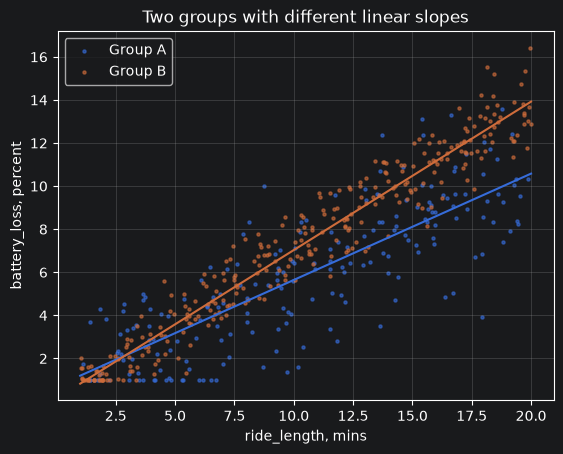

In [92]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n_1 = 200
n_2 = 300

# Генерация 1: более пологий линейный коэффициент
ride_1 = rng.uniform(1, 20, n_1)
rng.shuffle(ride_1)

battery_1 = (
    0 + 0.55 * ride_1 + rng.normal(0, 2, n_1)
).clip(1, 40)

# Генерация 2: более крутой линейный коэффициент
ride_2 = rng.uniform(1, 20, n_2)
rng.shuffle(ride_2)

battery_2 = (
    0 + 0.7 * ride_2 + rng.normal(0, 1, n_2)
).clip(1, 40)

# Объединяем генерации в один датасет
df = pd.concat([
    pd.DataFrame({
        "ride_length": ride_1,
        "battery_loss": battery_1,
        "group": "A"
    }),
    pd.DataFrame({
        "ride_length": ride_2,
        "battery_loss": battery_2,
        "group": "B"
    })
], ignore_index=True)

# Корреляции
print("Общая корреляция:",
      round(df["ride_length"].corr(df["battery_loss"]), 3))

print("\nКорреляции по группам:")
print(df.groupby("group")[["ride_length", "battery_loss"]]
      .corr().iloc[0::2, -1])

# Визуализация
for group, data in df.groupby("group"):
    plt.scatter(
        data["ride_length"],
        data["battery_loss"],
        alpha=0.6, s = 5,
        label=f"Group {group}"
    )

    # Линия линейной регрессии
    slope, intercept = np.polyfit(
        data["ride_length"], data["battery_loss"], 1
    )
    x = np.array([1, 20])
    plt.plot(x, slope * x + intercept)

plt.xlabel("ride_length, mins")
plt.ylabel("battery_loss, percent")
plt.title("Two groups with different linear slopes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()